# 6. The firm-growth facts, robustness, and the limits

Every fact of Moran, Secchi & Bouchaud (2024) at the reference point ($\alpha=2.5$, $\sigma=1.70$, $D=0.1$, $C=200$, $\mu=-1.76$),
from a production run of eight economies with $N=32000$. Each economy is simulated and reduced to its statistics by
`run_economy` (below; about an hour and a few GB each), stored in `data/demographic/robustness/<label>_seed<k>.npz`;
missing files are simulated on first use.

**Protocol** (notebook 01): lives with at least $n_{\min}$ yearly growth rates. The facts use $n_{\min}=20$: Compustat firms have
46 growth rates on average, and MSB find their results unchanged for firms with at least 20, while the model's lives with
few growth rates are mostly newborns. The robustness table and the last section use $n_{\min}=5$, where the range matters; $v=\sqrt{\pi/2}\times$ MAD,
exponents over 25 equal-count bins of $\bar S$, all bins included; "fifths" are fifths of life-mean size.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from joblib import Parallel, delayed
from economy import configuration_coupling, integrate_demographic, zeta_bins, hill, DATA, FIGURES, MSB_ZETA, MSB_RATIO, tidy

plt.rcParams.update({"figure.dpi": 110, "font.size": 9.5})

**One economy, reduced.** `run_economy` simulates (burn-in 100, window 480, sampled every 0.5) and keeps only per-life arrays
and summary statistics: lives ($\bar S$, MAD and SD volatility, growth count); by size fifth the excess kurtosis and
stretched-exponential tail exponent of rescaled growth (lives $\ge10$), the $k$-step persistence ratio (lives $\ge20$), the
correlation with the aggregate and the mean pairwise correlation within the fifth (40-step windows); aggregate volatility per
step; lag-1 autocorrelation of growth at steps 0.5, 1 and 2; the size distribution; turnover. Two streaming passes over firms
keep the memory at $O(NT)$ even for $10^7$ lives.

In [2]:
OUT = DATA / "demographic" / "robustness"
MU, START, TOBS, DT = 1.76, 100.0, 480.0, 0.5
BURST = 0.3   # aggregate volatility per step above which an economy is in a collective burst


def path(label, seed):
    return OUT / f"{label}_seed{seed}.npz"


def load(label, seeds=range(16)):
    return [np.load(path(label, s)) for s in seeds if path(label, s).exists()]


def kept(ds):
    """Drop economies in a collective burst (aggregate volatility above BURST)."""
    return [d for d in ds if float(d["aggvol"]) <= BURST]


def tail_exponent(z):
    """Stretched-exponential exponent of |z|: slope of log(-log P(|z|>x)) against log x over P in [1e-4, 1e-1]
    (1 = exponential tail, 2 = Gaussian)."""
    a = np.sort(np.abs(np.asarray(z, float)))[::-1]
    p = np.arange(1, a.size + 1) / a.size
    m = (p > 1e-4) & (p < 1e-1) & (a > 0)
    return float(np.polyfit(np.log(a[m]), np.log(-np.log(p[m])), 1)[0])


def _segs(Li, T):
    return [s for s in np.split(np.arange(T), np.flatnonzero(np.diff(Li)) + 1) if s.size >= 3]


def analyse(S, L, fbar, N, cap=400_000, seed=0):
    """Two streaming passes over firms, so memory stays O(N T) even for 10^7 lives."""
    out = {}
    lnS = np.log(S)
    T = S.shape[1]
    Sb, V, SD, NN = [], [], [], []
    for i in range(S.shape[0]):                                   # pass 1: per-life statistics
        segs = _segs(L[i], T)
        if not segs:
            continue
        g = [np.diff(lnS[i, s]).astype(float) for s in segs]
        Sb.append(np.array([S[i, s].mean() for s in segs], np.float32))
        V.append(np.array([np.sqrt(np.pi / 2) * np.abs(x - x.mean()).mean() for x in g], np.float32))
        SD.append(np.array([x.std(ddof=1) for x in g], np.float32))
        NN.append(np.array([x.size for x in g], np.int32))
    out["Sbar"], out["v"], out["sd"], out["n"] = (np.concatenate(Sb), np.concatenate(V), np.concatenate(SD),
                                                  np.concatenate(NN))
    ok = out["v"] > 0
    q10 = np.quantile(out["Sbar"][(out["n"] >= 10) & ok], [0.2, 0.4, 0.6, 0.8])
    q20 = np.quantile(out["Sbar"][(out["n"] >= 20) & ok], [0.2, 0.4, 0.6, 0.8])
    sel10 = (out["n"] >= 10) & ok
    cnt10 = np.bincount(np.digitize(out["Sbar"][sel10], q10), weights=out["n"][sel10], minlength=5)
    keep = np.minimum(1.0, cap / np.maximum(cnt10, 1))
    rng = np.random.default_rng(seed)
    m10 = np.zeros((5, 3))                                        # count, sum z^2, sum z^4
    sub = [[] for _ in range(5)]
    m20 = np.zeros((5, 4, 3))                                     # k = 1..4
    for i in range(S.shape[0]):                                   # pass 2: rescaled growth by size fifth
        for s in _segs(L[i], T):
            g = np.diff(lnS[i, s]).astype(float)
            if g.size < 10:
                continue
            r = g - g.mean()
            v = np.sqrt(np.pi / 2) * np.abs(r).mean()
            if v <= 0:
                continue
            z, sb = r / v, S[i, s].mean()
            f = int(np.digitize(sb, q10))
            m10[f] += (z.size, (z ** 2).sum(), (z ** 4).sum())
            if rng.random() < keep[f]:
                sub[f].append(z.astype(np.float32))
            if g.size >= 20:
                f2 = int(np.digitize(sb, q20))
                for j, k in enumerate((1, 2, 3, 4)):
                    zk = z[: z.size // k * k].reshape(-1, k).sum(1)
                    m20[f2, j] += (zk.size, (zk ** 2).sum(), (zk ** 4).sum())
    kurt = lambda m: m[..., 2] * m[..., 0] / m[..., 1] ** 2 - 3
    out["kurt"] = kurt(m10)
    out["tailexp"] = np.array([tail_exponent(np.concatenate(x)) for x in sub])
    k20 = kurt(m20)
    out["persist"] = np.array([[k20[f, j] / (k20[f, 0] / k) for j, k in ((1, 2), (2, 3), (3, 4))] for f in range(5)])
    G = fbar[:-1] * DT
    out["aggvol"] = float(np.std(G))
    g = np.diff(np.log(S), axis=1) + G[None, :].astype(np.float32)
    W, rng = 40, np.random.default_rng(0)
    ca, cp = [[] for _ in range(5)], [[] for _ in range(5)]
    for a in range(0, S.shape[1] - W - 1, W):
        idx = np.flatnonzero(np.all(L[:, a:a + W + 1] == L[:, [a]], axis=1))
        if idx.size < 100:
            continue
        ms = S[idx, a:a + W + 1].mean(1)
        q = np.digitize(ms, np.quantile(ms, [0.2, 0.4, 0.6, 0.8]))
        agg = G[a:a + W]
        for f5 in range(5):
            ii = idx[q == f5]
            if ii.size < 20:
                continue
            ii = rng.choice(ii, min(300, ii.size), replace=False)
            gg = g[ii, a:a + W].astype(float)
            ok = gg.std(1) > 0
            ca[f5] += [np.corrcoef(row, agg)[0, 1] for row in gg[ok]]
            c = np.corrcoef(gg[ok])
            cp[f5].append(np.nanmean(c[np.triu_indices_from(c, 1)]))
    out["corr_agg"] = np.array([np.nanmean(x) for x in ca])
    out["corr_pair"] = np.array([np.nanmean(x) for x in cp])
    lags = []
    for k in (1, 2, 4):
        Sk, Lk = S[:, ::k], L[:, ::k]
        gk = np.diff(np.log(Sk), axis=1)
        same = (Lk[:, 2:] == Lk[:, 1:-1]) & (Lk[:, 1:-1] == Lk[:, :-2])
        lags.append(np.corrcoef(gk[:, :-1][same], gk[:, 1:][same])[0, 1])
    out["lag1"] = np.array(lags)
    allS = S[:, ::5].ravel().astype(float)
    out["hill1"] = hill(allS, 0.01)
    lx = np.log10(allS)
    out["decades"] = np.array([np.mean((lx >= lo) & (lx < lo + 1)) for lo in range(-4, 2)])
    out["topshare"] = float(S.max(0).mean() / N)
    out["turnover"] = float((L[:, -1] - L[:, 0]).sum() / N / TOBS)
    return out


def run_economy(label, seed, *, alpha=2.5, sigma=1.70, D=0.1, N=32000, C=200, theta=1.0):
    """Simulate one economy and store its statistics; skipped if the file exists."""
    f = path(label, seed)
    if f.exists():
        return f
    t0 = time.time()
    a = configuration_coupling(N, MU, sigma, alpha=alpha, mean_degree=C, seed=seed)
    r = integrate_demographic(a, D=D, tmax=START + TOBS, t_start=START, dt_save=DT, seed=seed, compact=True,
                              theta=theta)
    S, L = r["S"], r["life"]
    del r
    Sth = lambda k: S[:, k].astype(float) ** theta
    fbar = np.array([float(S[:, k].astype(float) @ (1.0 - Sth(k) - a @ Sth(k))) / N for k in range(S.shape[1])])
    out = analyse(S, L, fbar, N)
    out["secs"] = time.time() - t0
    OUT.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(f, **out)
    return f

In [3]:
REF = dict(alpha=2.5, sigma=1.75, D=0.1, N=8000, C=200, theta=1.0)    # the point before the retune
JOBS = {  # label: (overrides of REF, seeds)
    "prod": ({"N": 32000, "sigma": 1.70}, range(8)),
    "ref": ({}, range(8)), "N16k": ({"N": 16000}, range(4)), "N32k": ({"N": 32000}, range(6)), "N64k": ({"N": 64000}, range(2)),
    "D.05": ({"D": 0.05}, range(4)), "D.2": ({"D": 0.2}, range(4)), "s1.7": ({"sigma": 1.7}, range(4)),
    "s1.8": ({"sigma": 1.8}, range(4)), "a3": ({"alpha": 3.0}, range(4)), "C100": ({"C": 100}, range(4)),
    "C400": ({"C": 400}, range(4)),
    **{f"rt_s{s}_D{D:g}": ({"N": 16000, "sigma": s, "D": D}, range(4)) for s in (1.7, 1.72) for D in (0.1, 0.15, 0.2)},
    **{f"th{t:g}": ({"N": 16000, "sigma": 1.70, "theta": t}, range(4)) for t in (0.5, 0.75, 1.5)},   # last section
    **{f"th0.5_s{s:g}": ({"N": 16000, "sigma": s, "theta": 0.5}, range(4)) for s in (1.9, 2.0)},
}


def params(label):
    p = dict(REF)
    p.update(JOBS[label][0])
    return p


def economies(label, run_missing=True):
    """The stored economies of a job; missing ones are simulated (largest jobs take hours: run them on a big machine)."""
    seeds = JOBS[label][1]
    if run_missing:
        todo = [s for s in seeds if not path(label, s).exists()]
        Parallel(n_jobs=min(len(todo), 8) or 1)(delayed(run_economy)(label, s, **params(label)) for s in todo)
    return load(label, seeds)

## The production run

In [4]:
all_prod = economies("prod")
ds = kept(all_prod)
cat = lambda ds, k: np.concatenate([d[k] for d in ds])
mean = lambda k: np.mean([d[k] for d in ds], 0)
sd = lambda k: np.std([d[k] for d in ds], 0)
for i, d in enumerate(all_prod):
    z = zeta_bins(d["Sbar"][d["n"] >= 5].astype(float), d["v"][d["n"] >= 5].astype(float))[0]
    print(f"economy {i}: aggregate volatility {float(d['aggvol']):.2f}, turnover {float(d['turnover']):.2f}, zeta_1 {z[0]:.2f}, "
          f"ratios {' '.join(f'{x:.2f}' for x in z[1:] / z[0])}{'   <- collective burst, excluded' if float(d['aggvol']) > BURST else ''}")

economy 0: aggregate volatility 0.05, turnover 0.61, zeta_1 0.20, ratios 1.95 2.80 3.54
economy 1: aggregate volatility 0.05, turnover 0.59, zeta_1 0.24, ratios 1.99 2.93 3.78


economy 2: aggregate volatility 0.06, turnover 0.59, zeta_1 0.19, ratios 1.92 2.69 3.30
economy 3: aggregate volatility 0.03, turnover 0.56, zeta_1 0.24, ratios 1.99 2.92 3.76


economy 4: aggregate volatility 0.23, turnover 0.59, zeta_1 0.21, ratios 1.83 2.43 2.82


economy 5: aggregate volatility 0.06, turnover 0.59, zeta_1 0.19, ratios 1.93 2.73 3.38
economy 6: aggregate volatility 0.09, turnover 0.65, zeta_1 0.19, ratios 1.93 2.72 3.34


economy 7: aggregate volatility 0.54, turnover 0.68, zeta_1 0.07, ratios 1.54 1.56 1.15   <- collective burst, excluded


One economy is in a **collective burst**: aggregate volatility several times the typical one, higher turnover, and volatility
that hardly depends on size. We exclude economies whose aggregate volatility per step exceeds $0.3$ (`kept`). Across all
80 economies of the robustness table, 5 exceed the threshold; what triggers a burst is open. With the burst included
the pooled exponents are lower, because the burst economy contributes the largest number of lives.

In [5]:
def facts(ds, label=""):
    Sb, v, s_, n = (cat(ds, k).astype(float) for k in ("Sbar", "v", "sd", "n"))
    rows = {}
    for nm, vol, tag in ((2, v, "MAD"), (5, v, "MAD"), (10, v, "MAD"), (20, v, "MAD"), (5, s_, "SD")):
        sel = (n >= nm) & (vol > 0)
        z, res, v0, v1, dec, loc = zeta_bins(Sb[sel], vol[sel])
        z1 = [zeta_bins(d["Sbar"][d["n"] >= nm].astype(float), d["v" if tag == "MAD" else "sd"][d["n"] >= nm].astype(float))[0][0] for d in ds]
        rows[(tag, nm)] = z
        print(f"  {tag} n>={nm:2d}: zeta {' '.join(f'{x:.3f}' for x in z)} (zeta_1 sd between economies {np.std(z1):.3f})  "
              f"ratios {' '.join(f'{x:.2f}' for x in z[1:] / z[0])}  vol {v0:.2f} -> {v1:.2f} over {dec:.1f} decades, top-bin residual {res:+.2f}")
    r = {}
    for nm in (2, 10, 20):
        sel = n >= nm
        P = np.array_split(np.argsort(Sb[sel]), 25)
        x = np.empty(sel.sum())
        for p in P:
            x[p] = v[sel][p] / v[sel][p].mean()
        r[nm] = x
    m = lambda k: np.mean([d[k] for d in ds], 0)
    print(f"  tail index b of v/E[v|Sbar] (Hill, top 5%): n>=2 {hill(r[2], 0.05):.2f}, n>=10 {hill(r[10], 0.05):.2f}, n>=20 {hill(r[20], 0.05):.2f}")
    print(f"  excess kurtosis of rescaled growth by fifth {' '.join(f'{x:.1f}' for x in m('kurt'))};  "
          f"3-year persistence (kurtosis / iid) {' '.join(f'{x:.2f}' for x in m('persist')[:, 1])}")
    print(f"  correlation with the aggregate {' '.join(f'{x:.2f}' for x in m('corr_agg'))};  pairwise, same fifth "
          f"{' '.join(f'{x:.2f}' for x in m('corr_pair'))}")
    print(f"  aggregate volatility per step {m('aggvol'):.3f};  lag-1 autocorrelation of growth at steps 0.5/1/2 "
          f"{' '.join(f'{x:+.2f}' for x in m('lag1'))};  turnover {m('turnover'):.3f}")
    print(f"  sizes: Hill index of the top 1% {m('hill1'):.1f}; firm-time per decade from 1e-4: {' '.join(f'{100 * x:.0f}%' for x in m('decades'))}")
    return rows


print(f"prod, {len(ds)} economies (burst excluded):")
F = facts(ds)
print(f"\nwith the burst economy ({len(all_prod)} economies):")
_ = facts(all_prod)
print(f"\nCompustat: zeta {MSB_ZETA}, ratios {MSB_RATIO[1:]}, volatility 1.22 -> 0.22 over 4 decades, b = 4.6")

prod, 7 economies (burst excluded):


  MAD n>= 2: zeta 0.178 0.431 0.706 0.968 (zeta_1 sd between economies 0.016)  ratios 2.42 3.96 5.43  vol 1.11 -> 0.44 over 2.1 decades, top-bin residual -0.10


  MAD n>= 5: zeta 0.205 0.394 0.554 0.679 (zeta_1 sd between economies 0.020)  ratios 1.92 2.70 3.31  vol 1.11 -> 0.40 over 2.0 decades, top-bin residual -0.07


  MAD n>=10: zeta 0.214 0.381 0.501 0.577 (zeta_1 sd between economies 0.022)  ratios 1.79 2.35 2.70  vol 0.91 -> 0.37 over 1.8 decades, top-bin residual -0.06


  MAD n>=20: zeta 0.249 0.443 0.587 0.688 (zeta_1 sd between economies 0.026)  ratios 1.78 2.35 2.76  vol 0.70 -> 0.32 over 1.4 decades, top-bin residual -0.02


...

  MAD n>= 5: zeta 0.167 0.297 0.378 0.411 (zeta_1 sd between economies 0.049)  ratios 1.78 2.26 2.46  vol 1.11 -> 0.50 over 2.0 decades, top-bin residual +0.03


  MAD n>=10: zeta 0.173 0.288 0.349 0.364 (zeta_1 sd between economies 0.050)  ratios 1.67 2.02 2.11  vol 0.91 -> 0.46 over 1.8 decades, top-bin residual +0.04


  MAD n>=20: zeta 0.201 0.336 0.412 0.439 (zeta_1 sd between economies 0.059)  ratios 1.67 2.04 2.18  vol 0.70 -> 0.39 over 1.4 decades, top-bin residual +0.06


  SD n>= 5: zeta 0.135 0.244 0.320 0.365 (zeta_1 sd between economies 0.050)  ratios 1.81 2.37 2.69  vol 1.18 -> 0.63 over 2.0 decades, top-bin residual +0.06


  tail index b of v/E[v|Sbar] (Hill, top 5%): n>=2 4.32, n>=10 5.31, n>=20 6.32
  excess kurtosis of rescaled growth by fifth 1.4 3.1 5.5 9.4 21.0;  3-year persistence (kurtosis / iid) 0.72 0.75 0.86 0.98 1.30
  correlation with the aggregate 0.15 0.19 0.23 0.26 0.32;  pairwise, same fifth 0.06 0.08 0.10 0.11 0.14
  aggregate volatility per step 0.138;  lag-1 autocorrelation of growth at steps 0.5/1/2 +0.14 +0.17 -0.02;  turnover 0.607
  sizes: Hill index of the top 1% 4.4; firm-time per decade from 1e-4: 1% 8% 36% 25% 31% 0%

Compustat: zeta [0.2  0.39 0.51 0.58], ratios [1.95 2.55 2.9 ], volatility 1.22 -> 0.22 over 4 decades, b = 4.6


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


'created' timestamp seems very low; regarding as unix timestamp


'modified' timestamp seems very low; regarding as unix timestamp


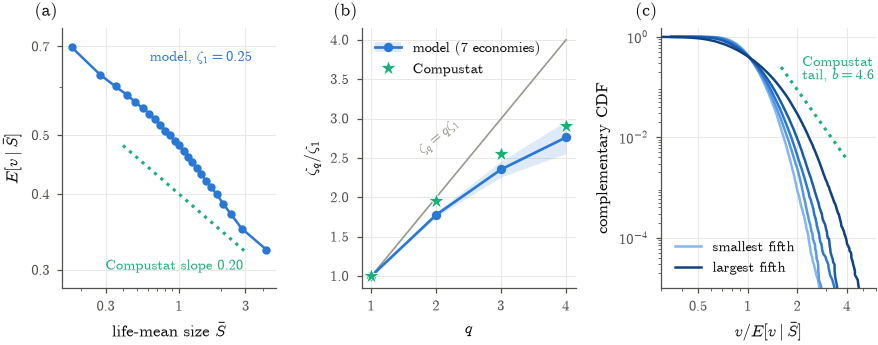

In [6]:
# Paper figure: the facts at n_min = 20. The by-fifth facts (Table I) are drawn below.
from economy import PAL, FIFTHS, COL1, COL2, paper_style, panel, save_paper
paper_style()
NM = 20
Sb, v, n = (cat(ds, k).astype(float) for k in ("Sbar", "v", "n"))
sel = (n >= NM) & (v > 0)
Sb, v = Sb[sel], v[sel]
P = np.array_split(np.argsort(Sb), 25)
xb, yb = np.array([Sb[p].mean() for p in P]), np.array([v[p].mean() for p in P])
z = zeta_bins(Sb, v)[0]
per = np.array([(lambda zz: zz / zz[0])(zeta_bins(d["Sbar"][d["n"] >= NM].astype(float), d["v"][d["n"] >= NM].astype(float))[0])
                for d in ds])
q = np.arange(1, 5)
fig, (a, b, c) = plt.subplots(1, 3, figsize=(COL2, 2.25), gridspec_kw=dict(wspace=0.4))
a.loglog(xb, yb, "o-", color=PAL["model"], ms=3, lw=1.2)
xg = np.geomspace(0.4, 3, 10)
a.loglog(xg, 0.40 * xg ** -MSB_ZETA[0], ":", color=PAL["data"], lw=1.5)
a.text(0.62, 0.66, rf"model, $\zeta_1={z[0]:.2f}$", color=PAL["model"], fontsize=7)
a.text(2.9, 0.312, rf"Compustat slope ${MSB_ZETA[0]:.2f}$", color=PAL["data"], fontsize=7, ha="right", va="top")
a.set(xlabel=r"life-mean size $\bar S$", ylabel=r"$E[v\mid\bar S]$", ylim=(0.28, 0.75))
tidy(a, [0.3, 1, 3], [0.3, 0.4, 0.5, 0.7])
b.plot(q, q, color=PAL["faint"], lw=0.8)
b.text(2.05, 2.55, r"$\zeta_q=q\zeta_1$", color=PAL["faint"], fontsize=7, ha="center", rotation=40)
band = b.fill_between(q, per.min(0), per.max(0), color=PAL["model"], alpha=0.15, lw=0)
ln, = b.plot(q, z / z[0], "o-", color=PAL["model"], ms=3.5, lw=1.3)
st, = b.plot(q, MSB_RATIO, "*", color=PAL["data"], ms=8, mec="white", mew=0.4, zorder=4)
b.legend([(band, ln), st], [f"model ({len(ds)} economies)", "Compustat"], loc="upper left")
b.set(xlabel=r"$q$", ylabel=r"$\zeta_q/\zeta_1$", xlim=(0.85, 4.15), ylim=(0.85, 4.15), xticks=q)
tidy(b)
r, grp = np.empty(v.size), np.empty(v.size, int)
for i, p in enumerate(P):
    r[p], grp[p] = v[p] / v[p].mean(), i // 5
cc = []
for f in range(5):
    x = np.sort(r[grp == f])[::-1]
    cc += c.loglog(x, np.arange(1, x.size + 1) / x.size, color=FIFTHS[f], lw=1.2)
xg = np.geomspace(1.6, 4, 10)
c.loglog(xg, 0.25 * (xg / 1.6) ** -4.6, ":", color=PAL["data"], lw=1.5)
c.text(2.15, 0.12, "Compustat\ntail, $b=4.6$", color=PAL["data"], fontsize=7, va="bottom")
c.set(xlabel=r"$v/E[v\mid\bar S]$", ylabel="complementary CDF", xlim=(0.3, 6), ylim=(1e-5, 1.5))
c.legend([cc[0], cc[4]], ["smallest fifth", "largest fifth"], loc="lower left")
tidy(c, [0.5, 1, 2, 4])
from matplotlib.ticker import LogFormatterMathtext
c.set_yticks([1e-4, 1e-2, 1])
c.yaxis.set_major_formatter(LogFormatterMathtext())
for ax, l in zip((a, b, c), "abc"):
    panel(ax, l)
save_paper(fig, "fig_facts")


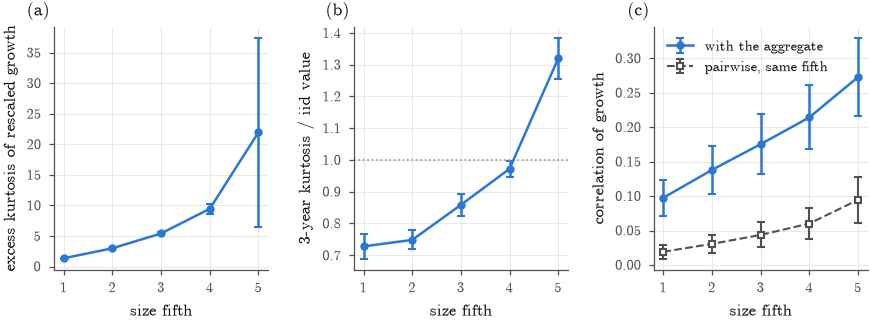

In [7]:
f5 = np.arange(1, 6)
fig, axs = plt.subplots(1, 3, figsize=(COL2, 2.1), gridspec_kw=dict(wspace=0.4))
for ax, key, lab in ((axs[0], "kurt", "excess kurtosis of rescaled growth"),
                     (axs[1], "persist", "3-year kurtosis / iid value"), (axs[2], "corr_agg", "correlation of growth")):
    y = mean(key)[:, 1] if key == "persist" else mean(key)
    e = sd(key)[:, 1] if key == "persist" else sd(key)
    ax.errorbar(f5, y, e, fmt="o-", color=PAL["model"], ms=3, lw=1.2, capsize=2, label="with the aggregate" if key == "corr_agg" else None)
    ax.set(xlabel="size fifth", ylabel=lab, xticks=f5)
axs[1].axhline(1, color=PAL["faint"], lw=0.8, ls=":")
axs[2].errorbar(f5, mean("corr_pair"), sd("corr_pair"), fmt="s--", color=PAL["muted"], ms=2.5, lw=1.0, capsize=2, mfc="white",
                label="pairwise, same fifth")
axs[2].legend(loc="upper left")
for ax, l in zip(axs, "abc"):
    tidy(ax)
    panel(ax, l)


**What the model explains.** $\sigma$ and $D$ were chosen so that $\zeta_1\simeq0.2$ for $n_{\min}=5$; for the facts sample
($n_{\min}=20$) $\zeta_1=0.25$, a little steeper than Compustat ($\zeta_1$ falls with $\sigma$, robustness table). The size–volatility
relation declines monotonically with no hump at small sizes, and the ratio curve bends below $q$ by about the empirical amount
($1.78$, $2.35$, $2.76$ against $1.95$, $2.55$, $2.90$), through the mechanism of notebook 05.
Co-movement with the aggregate and with firms of similar size rises with size, as in Compustat (a natural reading: small firms are
moved by their own noise, large ones by their field, which they share with their neighbours; no theory yet).

**What it does not.**
- *Short lives.* The results differ for very short lives. With all lives of at least two growth rates (MSB's baseline sample, in which
  Compustat firms still average 46) the ratios lie above $q$: very short lives are newborns dominated by their own noise, whose
  volatility estimates are dispersed most among the smallest firms. The bend appears from $n_{\min}\approx5$.
- *Large firms are too volatile and too fat-tailed.* Volatility falls by a factor $2.2$ over $1.4$ decades for $n_{\min}=20$ ($2.8$ over two
  decades for $n_{\min}=5$, which reaches smaller sizes), against $5.5$ over four in Compustat. Rescaled growth is nearly Gaussian for small firms and strongly fat-tailed for large ones, and multi-year persistence is
  confined to the largest: small firms are moved by near-Gaussian, mean-reverting birth–death noise, large firms by rare and persistent
  dips of their field.
- *The tail of the volatility distribution* (next section).
- *Aggregate volatility* is several times too large, and occasionally an economy bursts.
- *Sizes and demography.* No Pareto tail (last section), extreme infant mortality, small established firms shrink on average.

## Robustness

The sequence in $N$ and the neighbourhood were run at $\sigma=1.75$, the point before the retune; the retune scans $\sigma\in\{1.70,1.72\}$
and $D\in\{0.1,0.15,0.2\}$ at $N=16000$. (Jobs with $N<32000$ outside the retune used the networkx graph builder; `run_economy` always
uses the numpy one, same ensemble, different random stream.)

In [8]:
print(f"{'job':14} {'alpha':>5} {'sigma':>5} {'D':>5} {'N':>6} {'C':>4} econ | zeta_1 (n>=5)  ±sd   ratios         | b(n>=10) agg.vol turnover")
for label in JOBS:
    if label.startswith("th"):                                    # the theta jobs belong to the last section
        continue
    ds_ = kept(economies(label, run_missing=False))
    if not ds_:
        continue
    p = params(label)
    sel = lambda d: d["n"] >= 5
    Sb_, v_ = (np.concatenate([d[k][sel(d)] for d in ds_]).astype(float) for k in ("Sbar", "v"))
    z = zeta_bins(Sb_, v_)[0]
    z1 = np.std([zeta_bins(d["Sbar"][sel(d)].astype(float), d["v"][sel(d)].astype(float))[0][0] for d in ds_])
    n10 = np.concatenate([d["n"] for d in ds_]) >= 10
    Sb10, v10 = (np.concatenate([d[k] for d in ds_]).astype(float)[n10] for k in ("Sbar", "v"))
    P = np.array_split(np.argsort(Sb10), 25)
    rr = np.empty(v10.size)
    for pp in P:
        rr[pp] = v10[pp] / v10[pp].mean()
    print(f"{label:14} {p['alpha']:5.1f} {p['sigma']:5.2f} {p['D']:5.2f} {p['N']:6d} {p['C']:4d} {len(ds_):4d} | {z[0]:.3f}         {z1:.3f}  "
          f"{' '.join(f'{x:.2f}' for x in z[1:] / z[0])} | {hill(rr, 0.05):5.2f}   {np.mean([d['aggvol'] for d in ds_]):.3f}   "
          f"{np.mean([d['turnover'] for d in ds_]):.3f}")

job            alpha sigma     D      N    C econ | zeta_1 (n>=5)  ±sd   ratios         | b(n>=10) agg.vol turnover


prod             2.5  1.70  0.10  32000  200    7 | 0.205         0.020  1.92 2.70 3.31 |  5.53   0.081   0.597


ref              2.5  1.75  0.10   8000  200    8 | 0.188         0.039  1.91 2.67 3.28 |  5.75   0.088   0.686


N16k             2.5  1.75  0.10  16000  200    4 | 0.124         0.052  1.82 2.42 2.80 |  6.32   0.108   0.693


N32k             2.5  1.75  0.10  32000  200    5 | 0.123         0.030  1.83 2.42 2.78 |  6.26   0.112   0.678


...

rt_s1.7_D0.15    2.5  1.70  0.15  16000  200    4 | 0.232         0.020  1.98 2.88 3.66 |  5.94   0.060   0.585


rt_s1.7_D0.2     2.5  1.70  0.20  16000  200    4 | 0.251         0.018  2.00 2.94 3.79 |  6.11   0.056   0.583


rt_s1.72_D0.1    2.5  1.72  0.10  16000  200    4 | 0.171         0.024  1.88 2.56 3.05 |  5.69   0.111   0.620


rt_s1.72_D0.15   2.5  1.72  0.15  16000  200    4 | 0.202         0.024  1.93 2.72 3.33 |  5.90   0.094   0.615


rt_s1.72_D0.2    2.5  1.72  0.20  16000  200    4 | 0.238         0.012  1.99 2.91 3.70 |  6.14   0.070   0.602


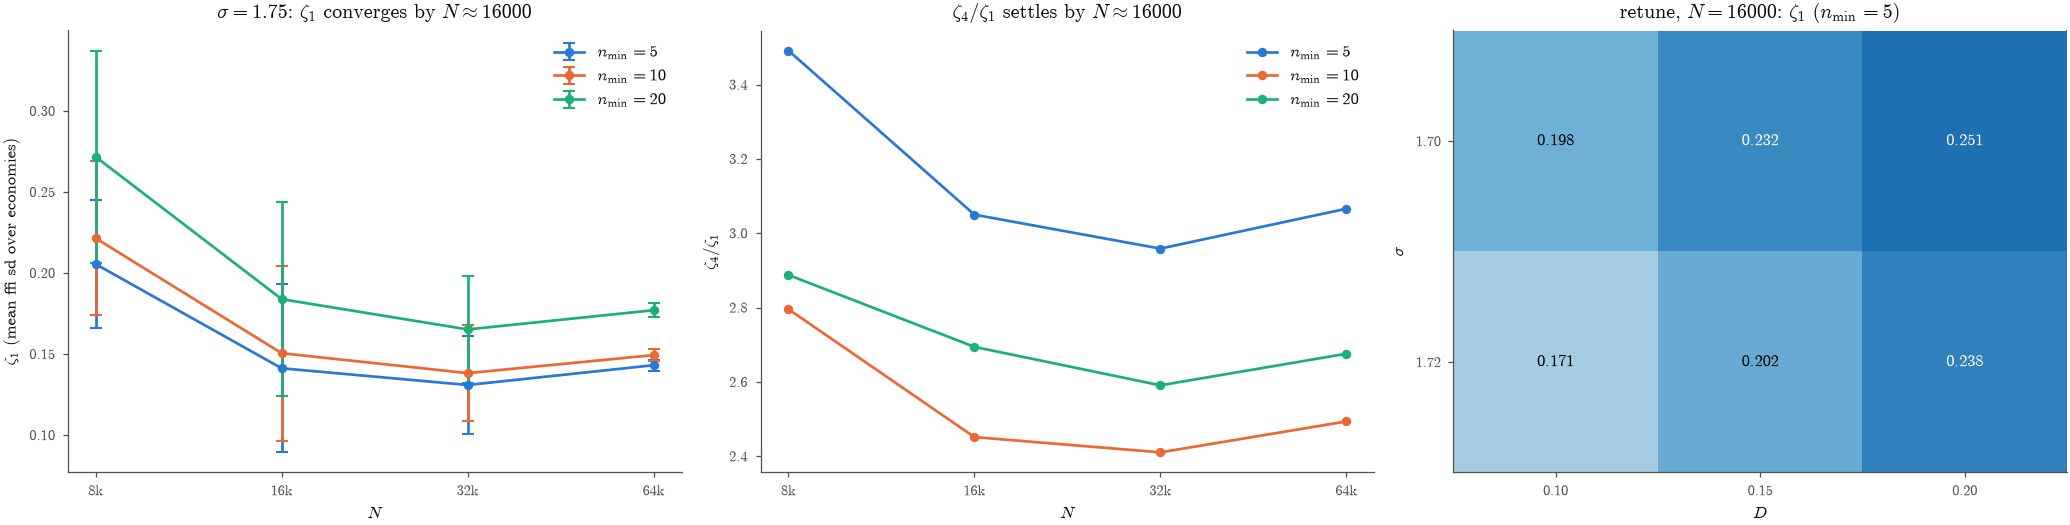

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.7))
Ns = {"ref": 8000, "N16k": 16000, "N32k": 32000, "N64k": 64000}
for nm, col in ((5, "#2a78d6"), (10, "#eb6834"), (20, "#1baf7a")):
    zs = []
    for label in Ns:
        dd = kept(economies(label, run_missing=False))
        per = [zeta_bins(d["Sbar"][d["n"] >= nm].astype(float), d["v"][d["n"] >= nm].astype(float))[0] for d in dd]
        zs.append((np.mean([z[0] for z in per]), np.std([z[0] for z in per]), np.mean([z[3] / z[0] for z in per])))
    zs = np.array(zs)
    ax[0].errorbar(list(Ns.values()), zs[:, 0], zs[:, 1], fmt="o-", color=col, capsize=3, label=rf"$n_{{\min}}={nm}$")
    ax[1].plot(list(Ns.values()), zs[:, 2], "o-", color=col, label=rf"$n_{{\min}}={nm}$")
ax[0].set(xscale="log", xlabel="$N$", ylabel=r"$\zeta_1$ (mean ± sd over economies)", title=r"$\sigma=1.75$: $\zeta_1$ converges by $N\approx16000$")
ax[1].set(xscale="log", xlabel="$N$", ylabel=r"$\zeta_4/\zeta_1$", title=r"$\zeta_4/\zeta_1$ settles by $N\approx16000$")
grid = np.full((2, 3), np.nan)
for i, s in enumerate((1.7, 1.72)):
    for j, D in enumerate((0.1, 0.15, 0.2)):
        dd = kept(economies(f"rt_s{s}_D{D:g}", run_missing=False))
        if dd:
            Sb_, v_ = (np.concatenate([d[k][d["n"] >= 5] for d in dd]).astype(float) for k in ("Sbar", "v"))
            grid[i, j] = zeta_bins(Sb_, v_)[0][0]
im = ax[2].imshow(grid, cmap="Blues", vmin=0.1, vmax=0.3, aspect="auto")
for (i, j), x in np.ndenumerate(grid):
    ax[2].text(j, i, f"{x:.3f}", ha="center", va="center", color="black" if x < 0.22 else "white")
ax[2].set(xticks=range(3), xticklabels=["0.10", "0.15", "0.20"], yticks=range(2), yticklabels=["1.70", "1.72"],
          xlabel="$D$", ylabel=r"$\sigma$", title=r"retune, $N=16000$: $\zeta_1$ ($n_{\min}=5$)")
for a in ax[:2]:
    a.xaxis.set_minor_locator(plt.NullLocator())
    a.set_xticks(list(Ns.values()), [f"{x // 1000}k" for x in Ns.values()])
    a.legend(frameon=False, fontsize=8)
    for s in ("top", "right"):
        a.spines[s].set_visible(False)
plt.tight_layout()

The shape of the curve survives $N=8000$–$64000$, different seeds and the neighbourhood of the reference point; $\zeta_1$ and the ratios
settle by $N\approx16000$ within the spread between economies ($\pm0.03$ in $\zeta_1$; the $N=8000$ graph is saturated, see below). $\sigma$, $D$ and $C$ set the level of $\zeta_1$: it
grows with $D$ (the crossover scale of notebook 04 grows with $D$) and falls with $\sigma$. At $N=8000$ the $\alpha=2.5$, $C=200$ graph is
saturated: merging multi-edges removes 40% of the edge ends. With the standard deviation instead of $\sqrt{\pi/2}\,$MAD, $\zeta_1$ is
about $0.03$ lower and the ratios higher (the SD rows above).

**The year.** We sample every $0.5$ time units. The lag-1 autocorrelation of growth within lives is about $+0.13$, $+0.18$ and $0.00$ at
steps $0.5$, $1$ and $2$ (printed above); a step of $2$ would remove it but leaves fewer growth rates per life. The two stored
reference economies (notebooks 04–05) keep their paths, so the panel can be redone at steps $1$ and $2$:

In [10]:
import economy as eco
from economy import lives

by_step = {}
for seed in eco.SEEDS:
    d = np.load(eco.simulate_reference(seed))
    S, L = d["S"].astype(float), d["L"]
    for k in (1, 2, 4):
        by_step.setdefault(k, []).extend(x[:3] for x in lives(S, L, k))
for k, lv in by_step.items():
    Sb_, v_, n_ = map(np.array, zip(*lv))
    for nm in (5, 20):
        sel = n_ >= nm
        z, _, v0, v1, dec, _ = zeta_bins(Sb_[sel], v_[sel])
        print(f"step {0.5 * k:3.1f}, n>={nm:2d}: {sel.sum():6d} lives  zeta {' '.join(f'{x:.3f}' for x in z)}  "
              f"ratios {' '.join(f'{x:.2f}' for x in z[1:] / z[0])}  vol {v0:.2f} -> {v1:.2f} over {dec:.1f} decades")

step 0.5, n>= 5: 625099 lives  zeta 0.209 0.405 0.572 0.702  ratios 1.94 2.74 3.36  vol 1.11 -> 0.38 over 2.0 decades
step 0.5, n>=20: 197636 lives  zeta 0.254 0.458 0.615 0.731  ratios 1.80 2.42 2.88  vol 0.69 -> 0.33 over 1.4 decades


step 1.0, n>= 5: 332984 lives  zeta 0.151 0.270 0.350 0.395  ratios 1.79 2.32 2.62  vol 1.11 -> 0.60 over 1.8 decades
step 1.0, n>=20:  96349 lives  zeta 0.231 0.412 0.547 0.642  ratios 1.78 2.36 2.78  vol 0.77 -> 0.46 over 1.1 decades
step 2.0, n>= 5: 185852 lives  zeta 0.156 0.270 0.339 0.370  ratios 1.73 2.17 2.36  vol 1.24 -> 0.83 over 1.4 decades


step 2.0, n>=20:  40912 lives  zeta 0.230 0.401 0.521 0.596  ratios 1.75 2.27 2.60  vol 0.91 -> 0.60 over 0.9 decades


At step $2$ the volatility per step rises by a factor $1.1$ in the smallest bin and $2.2$ in the largest: the decline flattens
($\zeta_1$ $0.21\to0.16$ for $n_{\min}=5$) and the ratio curve bends further below $q$. For $n_{\min}=20$ the change is smaller. The
bend below $q$ survives the coarser year; the level of $\zeta_1$ for short lives does not.

## The tail index $b$ and its null

For lives with at least two growth rates the model gives $b\approx4.4$ at every parameter point, close to the Compustat $4.6$. Null:
every life keeps its size and its number of growth rates, but its growth rates are iid draws with a true volatility that depends on size
only (the model's binned mean) — no differences between firms at all — and $v$ and $b$ are estimated exactly as for the model.

In [11]:
dd = economies("rt_s1.7_D0.1", run_missing=False)
Sb_, v_, n_ = (np.concatenate([d[k] for d in dd]) for k in ("Sbar", "v", "n"))
ok = v_ > 0
Sb_, v_, n_ = Sb_[ok].astype(float), v_[ok].astype(float), n_[ok]
P = np.array_split(np.argsort(Sb_), 25)
scale = np.empty(v_.size)
for p in P:
    scale[p] = v_[p].mean()


def ratio_b(Sb, v):
    P = np.array_split(np.argsort(Sb), 25)
    r = np.empty(v.size)
    for p in P:
        r[p] = v[p] / v[p].mean()
    return hill(r, 0.05)


def synth(draw, rng):
    out = np.empty(n_.size)
    for m in np.unique(n_):
        idx = np.flatnonzero(n_ == m)
        g = draw(rng, (idx.size, m)) * scale[idx, None]
        out[idx] = np.sqrt(np.pi / 2) * np.abs(g - g.mean(1, keepdims=True)).mean(1)
    return out


rng = np.random.default_rng(0)
print(f"{v_.size} lives (sigma 1.70, D 0.1, N 16000); share with 2, 3, 4 growth rates: "
      f"{np.mean(n_ == 2):.2f} {np.mean(n_ == 3):.2f} {np.mean(n_ == 4):.2f}")
print(f"{'':26} b(n>=2)  b(n>=5)  b(n>=10)  b(n>=20)")
for name, vv in (("model", v_), ("null: iid Gaussian", synth(lambda r, s: r.standard_normal(s), rng)),
                 ("null: iid Laplace", synth(lambda r, s: r.laplace(size=s), rng)),
                 ("null: iid Student t(3)", synth(lambda r, s: r.standard_t(3, size=s), rng))):
    print(f"{name:26} " + "  ".join(f"{ratio_b(Sb_[n_ >= m], vv[n_ >= m]):6.2f}" for m in (2, 5, 10, 20)))

3655280 lives (sigma 1.70, D 0.1, N 16000); share with 2, 3, 4 growth rates: 0.38 0.17 0.09
                           b(n>=2)  b(n>=5)  b(n>=10)  b(n>=20)


model                        4.40    5.27    5.68    6.88


null: iid Gaussian           5.73    9.08   12.84   17.35


null: iid Laplace            4.34    6.52    9.30   12.62


null: iid Student t(3)       3.00    3.88    5.28    7.15


The null with iid Laplace growth and no firm heterogeneity gives $b\approx4.3$ at $n_{\min}=2$: the model's apparent match is an estimator
effect of short lives. For longer lives the model's $b$ is higher than Compustat's and grows with $n_{\min}$ ($5.5$ at $n_{\min}=10$ and $6.8$ at
$n_{\min}=20$ in the production run, printed with the facts), while MSB find $4.6$ for all firms and for those with at least $20$
growth rates: the model's volatility distribution has too thin a tail.

## Why the range is short and there is no Zipf law

The self-limitation $-x_i/m$ does two jobs. It bounds a firm whose field stays favourable, which keeps the economy from condensing onto the
best niche; and its restoring rate is what makes volatility depend on size (the demographic part is filtered at rate $S$, and the floor is set
by how a firm on its plateau $x=m\Phi$ follows its field). Both rely on the plateau, and **the plateau caps firms at a few times the mean**:
the decline runs from a few times the newborn size $D$ to the plateau, about two decades. The size distribution has no Pareto tail
(Hill index $\approx4.5$ at the top 1%, against $\approx1$ for Zipf).

**The exponent and the range trade off.** Replace the self-limitation and the interactions by powers, $(x_i/m)^\theta$ and
$\sum_jJ_{ij}(x_j/m)^\theta$. Without noise, $u_i=S_i^\theta$ obeys the $\theta=1$ model with time rescaled by $\theta$, and since
$\ln S=\theta^{-1}\ln u$,

$$\zeta_1^{(S)}=\theta\,\zeta_1^{(u)},\qquad R_S=R_u/\theta,$$

with $R$ the number of decades over which volatility declines (exactly if a life's size is its geometric mean). A softer
self-limitation widens the range by the factor by which it flattens the decline: **the product $\zeta_1R$ is fixed by the statistics of the field**, about $0.3$–$0.4$ in the model against $0.8$ in
Compustat. Keeping the interactions linear while softening only the self-limitation condenses the economy.

**With noise.** The mapping ignores the noise: $\sqrt{DS}\,dW$ in $S$ becomes $\theta\sqrt D\,u^{1-1/2\theta}dW$ in $u$, additive at
$\theta=1/2$. Test: `run_economy` with `theta` (jobs `th*`, $N=16000$, four economies each) at the reference $\sigma$ and $D$, and for
$\theta=1/2$ also at larger $\sigma$. How much the field moves is measured on a small economy per point ($N=8000$, window 100): the
share of the field variance that is temporal, and the standard deviation of the growth rate of the mean firm.

In [12]:
def field_motion(theta, sigma, N=8000, seed=0):
    """Temporal share of the field variance and sd of fbar, window 100 after a burn-in of 100."""
    a = configuration_coupling(N, MU, sigma, alpha=2.5, mean_degree=200, seed=seed)
    r = integrate_demographic(a, D=0.1, tmax=200, t_start=100, dt_save=DT, seed=seed, theta=theta)
    St = r["S"] ** theta
    aS = a @ St
    fbar = (r["S"] * (1 - St - aS)).sum(0) / N
    Phi = 1 - aS - fbar
    return Phi.var(1).mean() / Phi.var(), fbar.std()


TH = {"rt_s1.7_D0.1": (1.0, 1.70), "th1.5": (1.5, 1.70), "th0.75": (0.75, 1.70), "th0.5": (0.5, 1.70),
      "th0.5_s1.9": (0.5, 1.90), "th0.5_s2": (0.5, 2.00)}
fm_path = DATA / "demographic" / "theta_field.npz"
if not fm_path.exists():
    fm = Parallel(n_jobs=len(TH))(delayed(field_motion)(t, s) for t, s in TH.values())
    np.savez(fm_path, **{k: np.array(x) for k, x in zip(TH, fm)})
fm = np.load(fm_path)
print(f"{'theta':>5} {'sigma':>5} econ | zeta_1  R (dec)  zeta_1 R (± sd) | ratios           | vol small -> large | agg.vol  "
      f"turnover  size Hill | field: temporal share  sd fbar")
for label, (t, s) in TH.items():
    ds_ = kept(economies(label))
    sel = lambda d: d["n"] >= 5
    Sb_, v_ = (np.concatenate([d[k][sel(d)] for d in ds_]).astype(float) for k in ("Sbar", "v"))
    z, _, v0, v1, dec, _ = zeta_bins(Sb_, v_)
    per = [zeta_bins(d["Sbar"][sel(d)].astype(float), d["v"][sel(d)].astype(float)) for d in ds_]
    zr = [p[0][0] * p[4] for p in per]
    print(f"{t:5.2f} {s:5.2f} {len(ds_):4d} | {z[0]:.3f}   {dec:.2f}     {z[0] * dec:.3f} ± {np.std(zr):.3f}  | "
          f"{' '.join(f'{x:.2f}' for x in z[1:] / z[0])}   | {v0:.2f} -> {v1:.2f}       | {np.mean([d['aggvol'] for d in ds_]):.3f}    "
          f"{np.mean([d['turnover'] for d in ds_]):.2f}     {np.mean([d['hill1'] for d in ds_]):.1f}     | "
          f"{fm[label][0]:.3f}                  {fm[label][1]:.3f}")

theta sigma econ | zeta_1  R (dec)  zeta_1 R (± sd) | ratios           | vol small -> large | agg.vol  turnover  size Hill | field: temporal share  sd fbar


 1.00  1.70    4 | 0.198   2.00     0.396 ± 0.036  | 1.93 2.71 3.32   | 1.11 -> 0.41       | 0.080    0.60     4.6     | 0.165                  0.240


 1.50  1.70    4 | 0.105   1.89     0.198 ± 0.039  | 1.75 2.21 2.41   | 1.12 -> 0.62       | 0.134    0.86     6.7     | 0.204                  0.335


 0.75  1.70    4 | 0.289   1.98     0.572 ± 0.034  | 2.03 3.05 4.05   | 1.11 -> 0.30       | 0.037    0.49     3.8     | 0.125                  0.137


 0.50  1.70    4 | 0.338   1.71     0.579 ± 0.009  | 2.08 3.24 4.45   | 1.11 -> 0.29       | 0.011    0.44     2.7     | 0.018                  0.041


 0.50  1.90    4 | 0.266   2.13     0.566 ± 0.025  | 2.05 3.12 4.18   | 1.12 -> 0.33       | 0.065    0.56     2.2     | 0.176                  0.145


 0.50  2.00    4 | 0.186   2.35     0.438 ± 0.007  | 2.02 3.01 3.94   | 1.12 -> 0.45       | 0.141    0.65     2.0     | 0.262                  0.315


**With noise the trade-off breaks.** At the reference $\sigma$ a softer self-limitation slows the field down (temporal share $0.17$ at
$\theta=1$, $0.02$ at $\theta=1/2$), volatility becomes demographic and the decline *steepens*: $\zeta_1=0.11$, $0.20$, $0.29$, $0.34$ for
$\theta=1.5$, $1$, $0.75$, $0.5$, while the range stays at $1.7$–$2.0$ decades. At $\theta=1/2$ the field moves as much as at the reference point
for $\sigma=1.9$, and there $\zeta_1=0.27$ over $2.1$ decades; at $\sigma=2.0$, $\zeta_1=0.19$ over $2.35$. The lower end of the range is set by the
newborn size: the smallest bin sits at $\bar S\simeq0.3D$ in every run (robustness table: $2.3$, $2.0$, $1.7$ decades for $D=0.05$, $0.1$, $0.2$
at $\theta=1$). The upper end is the plateau, about $3$ at $\theta=1$ and $1.6$–$6.7$ in the $\theta$ runs. The smallest lives have $v\simeq1.1$
whatever $D$, so $\zeta_1R\approx\log_{10}$ of the fall from there to the volatility of the largest firms: a factor $2.8$ at the reference point
against $5.5$ in Compustat; across $D$, $\zeta_1R$ stays at $0.35$–$0.43$ while the range moves. $\theta$ moves the floor and the plateau, and with
them the slope, the size tail (Hill $4.6\to2.0$) and the bend (ratios back to $q$ for $\theta<1$, further below for $\theta=1.5$), but in no run
does volatility fall by more than a factor $3.8$.

**Other ways out fail too** (details in `CEMETERY.md`). Without self-limitation growth is Gibrat-like, the condition under which a lower
barrier gives Zipf's law, but the quenched part of the field is not removed and the economy condenses onto the best niche. Giving each firm
its own moving capacity $K_i$ keeps the plateau but makes volatility depend only on $S_i/K_i$, so a Zipf law of capacities comes with
$\zeta_1=0$; making competitors act through their absolute sizes lets the largest firms dominate every field. A model with both a Zipf law and
a volatility law over four decades needs a size dependence of the dynamics that is not tied to a plateau, which in a one-variable model means
an explicit exponent. We read this as a limit of self-limited growth rather than of this particular model.

**Open problems.** A two-time theory with noise and turnover, which would give the field's correlation above $\sigma_c(D)$, the floor $v_F$
and $\zeta_1(\sigma,D)$ without simulation; the co-movement rising with size (the common mode of a finite economy); and a dynamics that
decouples the volatility decline from the size cap.